## Autism Classification Model Evaluation

# Project overview
This notebook compares traditional machine-learning models and a TensorFlow/Keras neural network using the 2022 National Survey of Children's Health (NSCH) topical dataset.

 The target represents caregiver-reported history of a healthcare provider
telling them that the child had autism/ASD. This model predicts reported status in survey data; it is not a clinical diagnostic or screening tool.

## 1. Imports and data loading
The following cells load the libraries, upload the downloaded NSCH ZIP file, and read the Stata dataset. Run the notebook from top to bottom after starting a fresh Colab runtime.

In [1]:
import pandas as pd
import numpy as np
import zipfile
import os
from google.colab import files

print("Environment ready!")

Environment ready!


In [2]:
uploaded = files.upload()
zip_path = next(iter(uploaded))

with zipfile.ZipFile(zip_path, "r") as z:
    print("Files inside the downloaded ZIP:")
    for name in z.namelist():
        print(name)

Saving nsch_2022_topical_Stata.zip to nsch_2022_topical_Stata.zip
Files inside the downloaded ZIP:
nsch_2022e_topical.dta
nsch_2022_topical.do


In [3]:

import zipfile
import pandas as pd


zip_path = "/content/nsch_2022_topical_Stata.zip"

with zipfile.ZipFile(zip_path, "r") as z:
    with z.open("nsch_2022e_topical.dta") as file:
        df = pd.read_stata(file)


print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])


display(df.head())


autism_columns = [
    col for col in df.columns
    if "autis" in col.lower()
]

print("\nAutism-related columns:")
print(autism_columns)


Number of rows: 54103
Number of columns: 484


,fipsst,stratum,hhid,formtype,totkids_r,tenure,hhlanguage,sc_age_years,sc_sex,k2q35a_1_years,...,higrade_tvis,fpl_i1,fpl_i2,fpl_i3,fpl_i4,fpl_i5,fpl_i6,fwc,height,weight
0,48,1,22000005,T1,2,3,1.0,5,1,NaN,...,4,400,400,80,94,365,104,2849.404193,NaN,NaN
1,48,1,22000021,T2,1,1,1.0,8,2,NaN,...,4,50,50,50,50,50,50,3498.887010,NaN,22.68
2,17,2A,22000034,T1,3,2,1.0,5,2,NaN,...,3,50,50,50,50,50,50,8377.672511,NaN,NaN
3,39,1,22000037,T2,2,3,1.0,6,2,NaN,...,3,200,200,200,200,200,200,1432.829521,121.92,22.68
4,28,1,22000053,T3,1,2,1.0,17,1,NaN,...,3,234,234,234,234,234,234,475.250016,167.63,61.23



Autism-related columns:
['autismmed', 'autismtreat']


## 2. Inspect target variables
Review the survey's autism-related target-question variables and their response codes before creating the binary outcome.

In [4]:
cols = [
    col for col in df.columns
    if col.lower().startswith("k2q35")
]

print("Relevant variables:", cols)


for col in cols:
    print(f"\n--- {col} ---")
    print(df[col].value_counts(dropna=False).head(15))


Relevant variables: ['k2q35a_1_years', 'k2q35a', 'k2q35b', 'k2q35c', 'k2q35d']

--- k2q35a_1_years ---
k2q35a_1_years
NaN     52329
2.0       408
3.0       354
4.0       215
5.0       160
6.0       111
8.0        94
1.0        88
7.0        80
15.0       47
12.0       47
10.0       45
9.0        43
11.0       37
13.0       24
Name: count, dtype: int64

--- k2q35a ---
k2q35a
2.0    51917
1.0     1908
NaN      278
Name: count, dtype: int64

--- k2q35b ---
k2q35b
NaN    52203
1.0     1788
2.0      112
Name: count, dtype: int64

--- k2q35c ---
k2q35c
NaN    52330
1.0      861
2.0      714
3.0      198
Name: count, dtype: int64

--- k2q35d ---
k2q35d
NaN    52213
2.0      673
4.0      339
1.0      300
5.0      191
3.0      190
6.0      158
7.0       39
Name: count, dtype: int64


## 3. Create the binary target
The analysis retains records where `k2q35a` has a valid response of 1 or 2, then maps those responses to a binary target. Check the printed distribution to understand the class imbalance.

In [5]:
data = df[df["k2q35a"].isin([1, 2])].copy()

data["target"] = data["k2q35a"].map({1: 1, 2: 0})

print("Records available:", len(data))
print("\nTarget distribution:")
print(data["target"].value_counts())
print("\nTarget proportions:")
print(data["target"].value_counts(normalize=True).round(3))


Records available: 53825

Target distribution:
target
0    51917
1     1908
Name: count, dtype: int64

Target proportions:
target
0    0.965
1    0.035
Name: proportion, dtype: float64


## 4. Exclude leakage-prone variables and split the data
This stage removes the target and autism-related survey variables from the predictors, then creates a stratified 80/20 train/test split. Stratification helps preserve the target proportions across the splits.

In [6]:
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

leakage_cols = [
    col for col in data.columns
    if "autis" in col.lower() or "k2q35" in col.lower()
]

print("Excluded autism-related variables:", leakage_cols)

X = data.drop(
    columns=["target"] + leakage_cols + ["hhid", "fwc"],
    errors="ignore"
)

y = data["target"]

X = X.select_dtypes(include=["number", "object", "category"])


X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

numeric_cols = X_train.select_dtypes(include=["number"]).columns
categorical_cols = X_train.select_dtypes(
    include=["object", "category"]
).columns

preprocessor = ColumnTransformer([
    ("numeric", Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ]), numeric_cols),
    ("categorical", Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("encoder", OneHotEncoder(handle_unknown="ignore"))
    ]), categorical_cols)
])

print("\nTraining records:", len(X_train))
print("Testing records:", len(X_test))
print("Remaining features:", X_train.shape[1])


Excluded autism-related variables: ['k2q35a_1_years', 'k2q35a', 'k2q35b', 'autismmed', 'autismtreat', 'k2q35c', 'k2q35d']

Training records: 43060
Testing records: 10765
Remaining features: 475


## 5. Baseline model comparison
Logistic Regression and Random Forest are trained with the same preprocessing pipeline. The comparison reports accuracy, precision, recall, F1-score, and ROC-AUC. Because the positive class is uncommon, interpret accuracy alongside recall, F1-score, and ROC-AUC.

In [7]:
from sklearn.base import clone
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score
)
import pandas as pd

models = {
    "Logistic Regression": LogisticRegression(
        class_weight="balanced",
        max_iter=1000,
        random_state=42
    ),
    "Random Forest": RandomForestClassifier(
        n_estimators=200,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    )
}

results = []
trained_models = {}

for name, model in models.items():
    pipeline = Pipeline([
        ("preprocessor", clone(preprocessor)),
        ("model", model)
    ])

    pipeline.fit(X_train, y_train)

    predictions = pipeline.predict(X_test)
    probabilities = pipeline.predict_proba(X_test)[:, 1]

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision": precision_score(y_test, predictions, zero_division=0),
        "Recall": recall_score(y_test, predictions, zero_division=0),
        "F1-score": f1_score(y_test, predictions, zero_division=0),
        "ROC-AUC": roc_auc_score(y_test, probabilities)
    })

    trained_models[name] = pipeline

results_df = pd.DataFrame(results).set_index("Model")
display(results_df.round(3))

,Accuracy,Precision,Recall,F1-score,ROC-AUC
Model,,,,,
Logistic Regression,0.932,0.327,0.861,0.474,0.964
Random Forest,0.969,0.795,0.183,0.298,0.969


## 6. Logistic Regression hyperparameter tuning
Grid search with stratified three-fold cross-validation selects the Logistic Regression settings using average precision, a useful metric for an imbalanced binary target. The final test set is used only for evaluation after tuning.

In [8]:

from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.metrics import classification_report, roc_auc_score

logistic_pipeline = trained_models["Logistic Regression"]

param_grid = {
    "model__C": [0.01, 0.1, 1, 10],
    "model__class_weight": ["balanced", None]
}

cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=42)

search = GridSearchCV(
    logistic_pipeline,
    param_grid,
    scoring="average_precision",
    cv=cv,
    n_jobs=-1,
    verbose=1
)

search.fit(X_train, y_train)

best_model = search.best_estimator_
predictions = best_model.predict(X_test)
probabilities = best_model.predict_proba(X_test)[:, 1]

print("Best parameters:", search.best_params_)
print("Best cross-validation average precision:", round(search.best_score_, 3))
print("\nTest classification report:")
print(classification_report(y_test, predictions, zero_division=0))
print("Test ROC-AUC:", round(roc_auc_score(y_test, probabilities), 3))


Fitting 3 folds for each of 8 candidates, totalling 24 fits
Best parameters: {'model__C': 0.01, 'model__class_weight': None}
Best cross-validation average precision: 0.626

Test classification report:
              precision    recall  f1-score   support

           0       0.98      0.99      0.99     10383
           1       0.70      0.46      0.55       382

    accuracy                           0.97     10765
   macro avg       0.84      0.73      0.77     10765
weighted avg       0.97      0.97      0.97     10765

Test ROC-AUC: 0.97


## 7. Prepare data for TensorFlow/Keras
The same leakage-safe feature set is transformed for the neural network. Preprocessing is fitted on the training set only, and then applied to the test set. The train/validation split is made from the processed training data below.

In [9]:
import tensorflow as tf
import numpy as np
from sklearn.base import clone

# Fit preprocessing on the training data only, then apply it to the test data.
nn_preprocessor = clone(preprocessor)
X_train_processed = nn_preprocessor.fit_transform(X_train).astype("float32")
X_test_processed = nn_preprocessor.transform(X_test).astype("float32")

y_train_np = y_train.to_numpy().astype("float32")
y_test_np = y_test.to_numpy().astype("int32")

print("Processed training shape:", X_train_processed.shape)
print("Processed test shape:", X_test_processed.shape)

Processed training shape: (43060, 478)
Processed test shape: (10765, 478)


### 7.1 Create a validation subset
A stratified validation subset is separated from the training data for monitoring generalization and early stopping. The test set remains separate for the final evaluation.

In [10]:

from sklearn.model_selection import train_test_split

X_fit, X_val, y_fit, y_val = train_test_split(
    X_train_processed,
    y_train_np,
    test_size=0.15,
    random_state=42,
    stratify=y_train_np
)

print("Training samples:", len(X_fit))
print("Validation samples:", len(X_val))

Training samples: 36601
Validation samples: 6459


### 7.2 Build `tf.data` datasets
`tf.data` batches and shuffles the fit subset and batches the validation subset for Keras training.

In [11]:
import tensorflow as tf

train_ds = tf.data.Dataset.from_tensor_slices(
    (X_fit, y_fit)
).shuffle(10000, seed=42).batch(256).prefetch(tf.data.AUTOTUNE)

val_ds = tf.data.Dataset.from_tensor_slices(
    (X_val, y_val)
).batch(256).prefetch(tf.data.AUTOTUNE)

print("TensorFlow training and validation datasets are ready.")

TensorFlow training and validation datasets are ready.


### 7.3 Train the neural network
A fresh model is initialized and trained only on `train_ds`; `val_ds` is used for validation and early stopping. This avoids reusing a model that has already trained on validation records.

In [12]:

model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(X_fit.shape[1],)),
    tf.keras.layers.Dense(128, activation="relu"),
    tf.keras.layers.Dropout(0.3),
    tf.keras.layers.Dense(64, activation="relu"),
    tf.keras.layers.Dropout(0.2),
    tf.keras.layers.Dense(1, activation="sigmoid")
])

model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=[
        tf.keras.metrics.BinaryAccuracy(name="accuracy"),
        tf.keras.metrics.AUC(name="auc")
    ]
)

early_stop = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=3,
    restore_best_weights=True
)

history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=20,
    callbacks=[early_stop],
    verbose=1
)

Epoch 1/20
143/143 ━━━━━━━━━━━━━━━━━━━━ 3s 13ms/step - accuracy: 0.9607 - auc: 0.8980 - loss: 0.1121 - val_accuracy: 0.9740 - val_auc: 0.9606 - val_loss: 0.0696
Epoch 2/20
143/143 ━━━━━━━━━━━━━━━━━━━━ 2s 14ms/step - accuracy: 0.9732 - auc: 0.9619 - loss: 0.0705 - val_accuracy: 0.9746 - val_auc: 0.9609 - val_loss: 0.0692
Epoch 3/20
143/143 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - accuracy: 0.9768 - auc: 0.9759 - loss: 0.0588 - val_accuracy: 0.9743 - val_auc: 0.9535 - val_loss: 0.0726
Epoch 4/20
143/143 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - accuracy: 0.9802 - auc: 0.9821 - loss: 0.0515 - val_accuracy: 0.9749 - val_auc: 0.9471 - val_loss: 0.0735
Epoch 5/20
143/143 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - accuracy: 0.9826 - auc: 0.9864 - loss: 0.0441 - val_accuracy: 0.9751 - val_auc: 0.9395 - val_loss: 0.0780


### 7.4 Evaluate the neural network on the test set
The trained network predicts the untouched test set. The classification report, average precision, and ROC-AUC summarize performance.

In [13]:

from sklearn.metrics import (
    classification_report,
    average_precision_score,
    roc_auc_score
)

nn_probabilities = model.predict(
    X_test_processed, verbose=0
).ravel()

nn_predictions = (nn_probabilities >= 0.5).astype(int)

print("Classification Report:")
print(classification_report(
    y_test_np, nn_predictions, zero_division=0
))

print("Test Average Precision:",
      round(average_precision_score(y_test_np, nn_probabilities), 3))

print("Test ROC-AUC:",
      round(roc_auc_score(y_test_np, nn_probabilities), 3))


Classification Report:
              precision    recall  f1-score   support

           0       0.98      0.99      0.99     10383
           1       0.72      0.47      0.57       382

    accuracy                           0.97     10765
   macro avg       0.85      0.73      0.78     10765
weighted avg       0.97      0.97      0.97     10765

Test Average Precision: 0.618
Test ROC-AUC: 0.964


## 7.5 Visual evaluation
The following cell plots neural-network training and validation curves, compares ROC curves across models, and displays confusion matrices. Run it after the model evaluation and after the tuned Logistic Regression cell has completed successfully.

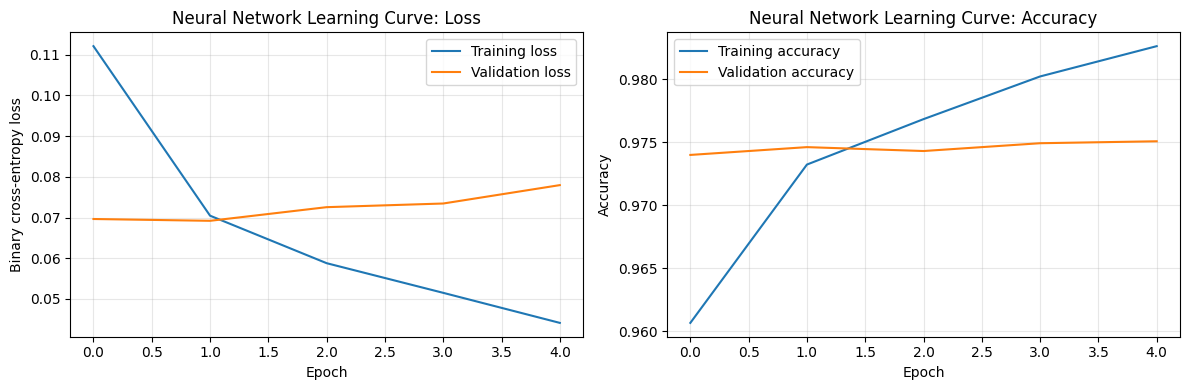

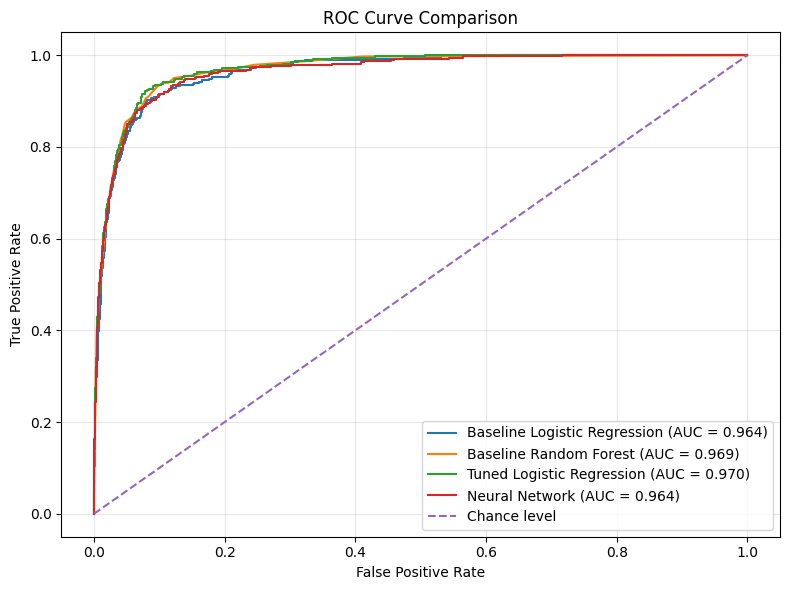

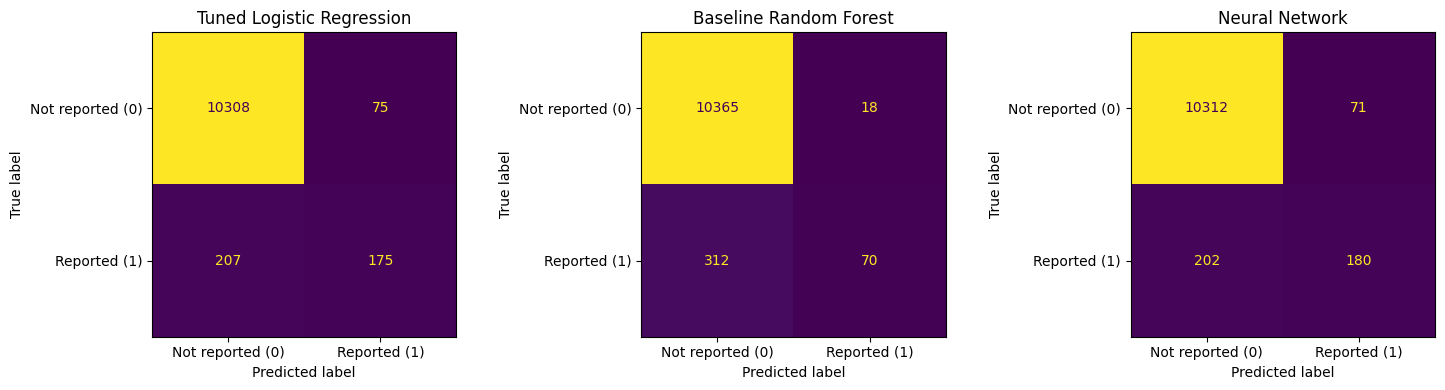

In [14]:
# Visual evaluation: learning curves, ROC curves, and confusion matrices
import matplotlib.pyplot as plt
from sklearn.metrics import (
    roc_curve, roc_auc_score, confusion_matrix, ConfusionMatrixDisplay
)

# 1. Neural-network learning curves
history_dict = history.history

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(history_dict["loss"], label="Training loss")
if "val_loss" in history_dict:
    axes[0].plot(history_dict["val_loss"], label="Validation loss")
axes[0].set_title("Neural Network Learning Curve: Loss")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Binary cross-entropy loss")
axes[0].legend()
axes[0].grid(True, alpha=0.3)

if "accuracy" in history_dict:
    axes[1].plot(history_dict["accuracy"], label="Training accuracy")
if "val_accuracy" in history_dict:
    axes[1].plot(history_dict["val_accuracy"], label="Validation accuracy")
axes[1].set_title("Neural Network Learning Curve: Accuracy")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Accuracy")
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

# 2. ROC curves for the baseline models, tuned Logistic Regression, and neural network
roc_models = {
    "Baseline Logistic Regression": trained_models["Logistic Regression"],
    "Baseline Random Forest": trained_models["Random Forest"],
    "Tuned Logistic Regression": best_model,
}
roc_probabilities = {
    name: estimator.predict_proba(X_test)[:, 1]
    for name, estimator in roc_models.items()
}
roc_probabilities["Neural Network"] = nn_probabilities

plt.figure(figsize=(8, 6))
for name, probabilities in roc_probabilities.items():
    fpr, tpr, _ = roc_curve(y_test, probabilities)
    auc_value = roc_auc_score(y_test, probabilities)
    plt.plot(fpr, tpr, label=f"{name} (AUC = {auc_value:.3f})")

plt.plot([0, 1], [0, 1], linestyle="--", label="Chance level")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve Comparison")
plt.legend(loc="lower right")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# 3. Confusion matrices at each model's default 0.5 / class prediction threshold
confusion_models = {
    "Tuned Logistic Regression": best_model.predict(X_test),
    "Baseline Random Forest": trained_models["Random Forest"].predict(X_test),
    "Neural Network": nn_predictions,
}

fig, axes = plt.subplots(1, len(confusion_models), figsize=(15, 4))
for ax, (name, predictions) in zip(axes, confusion_models.items()):
    cm = confusion_matrix(y_test, predictions, labels=[0, 1])
    ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=["Not reported (0)", "Reported (1)"]
    ).plot(ax=ax, values_format="d", colorbar=False)
    ax.set_title(name)

plt.tight_layout()
plt.show()


## 8. Save the trained models
Run this cell after model training and evaluation to save the tuned traditional model and the neural network. The downloaded files can then be uploaded to the project Google Drive folder.

In [15]:
# Save the best traditional ML model and the trained neural network
import joblib

joblib.dump(best_model, "best_logistic_regression_model.joblib")
model.save("autism_neural_network.keras")

print("Saved files:")
print("- best_logistic_regression_model.joblib")
print("- autism_neural_network.keras")

# In Google Colab, these lines download the saved files to your computer.
from google.colab import files
files.download("best_logistic_regression_model.joblib")
files.download("autism_neural_network.keras")


Saved files:
- best_logistic_regression_model.joblib
- autism_neural_network.keras


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 8. Leakage and split checks
These checks help confirm that autism-related variables were excluded from predictors and that the target proportions remain similar across training, validation, and test sets.

In [16]:

suspect_columns = [
    col for col in X_train.columns
    if any(term in col.lower() for term in [
        "autis", "k2q35", "diagnos", "condition"
    ])
]

print("Potentially suspicious features:")
print(suspect_columns)

print("\nNumber of input features:", X_train.shape[1])

Potentially suspicious features:
[]

Number of input features: 475


In [17]:

print("Target included in X:", "target" in X_train.columns)
print("Training rows:", len(X_train))
print("Validation rows:", len(X_val))
print("Test rows:", len(X_test))

print("\nTarget distribution in each set:")
print("Train:", y_train.value_counts(normalize=True).round(3).to_dict())
print("Validation:", pd.Series(y_val).value_counts(normalize=True).round(3).to_dict())
print("Test:", y_test.value_counts(normalize=True).round(3).to_dict())

Target included in X: False
Training rows: 43060
Validation rows: 6459
Test rows: 10765

Target distribution in each set:
Train: {0: 0.965, 1: 0.035}
Validation: {0.0: 0.965, 1.0: 0.035}
Test: {0: 0.965, 1: 0.035}


In [18]:

excluded_check = [
    "k2q35a", "k2q35b", "k2q35c", "k2q35d",
    "k2q35a_1_years", "hhid", "fwc"
]

print("Excluded variables still in X:")
print([c for c in excluded_check if c in X_train.columns])

print("\nAutism-related columns still in X:")
print([c for c in X_train.columns if "autis" in c.lower()])

Excluded variables still in X:
[]

Autism-related columns still in X:
[]


## 9. Interpretation and limitations

The models identified patterns linked to caregiver-reported autism/ASD diagnosis status, but they differed in how well they identified positive cases. Since only about 3.5% of the records were positive, accuracy alone is not enough to judge performance.

The results are based on reported diagnosis history, not verified clinical diagnoses. Missing data and survey limitations may also affect the results. These models should not be used to diagnose children, and further testing is needed to determine whether they work well with other populations.